# **PCA+GMM Method for Music Style Transformation**
PCA reduces high-dimensional audio patches into a compact, shared feature space,
while GMM models the timbre distribution of each style. Together, they enable lightweight and interpretable style transfer.

## **Training Section**
1. Data Processing
    - download .pt files
        - include 4k mel dataset of 10 sec Folk and Jazz musics
    - normalization
        - use StandardScaler
    - data segmentation
        - cut each sample into 60 patches of (80,20) segments
        - flatten each patch into (,1600)

2. PCA
    - n-components evaluation
        - method: reconstruction error (MSE)
        - result
    - PCA model
        - input data: scaled flatten patches of all samples
    - data generating
        - folk_pca and jazz_pca datasets

3. GMM
    - k-clusters evaluation
        - method: Bayesian information criterion (BIC)
        - result
    - GMM model
        - gmm_folk: input folk_pca
        - gmm_jazz: input jazz_pca
    - mapping
        - mapping clusters between two gmm models
        - method: Hungarian mapping


### **Data Processing**


In [ ]:
import torch
import numpy as np
from sklearn.preprocessing import StandardScaler
import joblib

#### download .pt files

In [ ]:
folk = torch.load("/content/folkdataset.pt")
jazz = torch.load("/content/jazzdataset.pt")

folk_mels = folk['folk_feature'].numpy()  # torch.Size([2207, 80, 616])
jazz_mels = jazz['jazz_feature'].numpy()  # torch.Size([2066, 80, 616])

#### normalization

In [ ]:
all_mels = np.concatenate([folk_mels, jazz_mels], axis=0)
all_frames = all_mels.transpose(0, 2, 1).reshape(-1, 80)

scaler = StandardScaler()
scaler.fit(all_frames)

In [ ]:
def apply_scaler_to_mels(mels, scaler):
    """
    mels: (N, 80, 616)
    return: normalized mels, shape (N, 80, 616)
    """
    N = mels.shape[0]

    # reshape to (-1, 80)
    frames = mels.transpose(0, 2, 1).reshape(-1, 80)

    # apply scaler
    frames_norm = scaler.transform(frames)   # (N*616, 80)

    # reshape back to (N, 80, 616)
    mels_norm = frames_norm.reshape(N, 616, 80).transpose(0, 2, 1)

    return mels_norm

In [ ]:
folk_mels_norm = apply_scaler_to_mels(folk_mels, scaler)
jazz_mels_norm = apply_scaler_to_mels(jazz_mels, scaler)

#### data segmentation

In [ ]:
def extract_patches_from_sample(mel, patch_size=20, hop=10):
    """
    mel: (80, 616)
    return: list of patches, each (80,20)
    """
    patches = []
    T = mel.shape[1]

    for start in range(0, T - patch_size + 1, hop):
        end = start + patch_size
        p = mel[:, start:end]    # (80,20)
        patches.append(p)

    return patches

def build_patch_dataset(mels, patch_size=20, hop=10):
    """
    mels: (N, 80, 616)
    return: flattened patches, shape (num_patches, 1600)
    """
    flat_patches = []

    for mel in mels:
        patches = extract_patches_from_sample(mel, patch_size, hop)
        for p in patches:
            flat_patches.append(p.reshape(-1))   # flatten to (1600,)

    return np.array(flat_patches)

In [ ]:
folk_patches = build_patch_dataset(folk_mels_norm, patch_size=20, hop=10)
jazz_patches = build_patch_dataset(jazz_mels_norm, patch_size=20, hop=10)

all_patches = np.concatenate([folk_patches, jazz_patches], axis=0)

### **PCA**

In [1]:
import numpy as np
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
import joblib

#### n-components evaluation

In [ ]:
# --- Part 1: Evaluate PCA Components (Reconstruction Error) ---
print("Evaluating PCA Components using Reconstruction Error...")

# Define a range of PCA components to test (powers of 2 up to 2^7 = 128)
pca_components_range = [2**i for i in range(1, 8)] # [2, 4, 8, 16, 32, 64, 128]
reconstruction_errors = []

for n_components in pca_components_range:
    # Initialize PCA with the current number of components
    pca = PCA(n_components=n_components)

    # Fit PCA on the scaled data
    pca.fit(all_patches)

    # Transform the data to lower dimension
    transformed_data = pca.transform(all_patches)

    # Inverse transform to reconstruct the data
    reconstructed_data = pca.inverse_transform(transformed_data)

    # Calculate the mean squared error (reconstruction error)
    mse = np.mean((all_patches - reconstructed_data)**2)
    reconstruction_errors.append(mse)
    print(f"PCA components: {n_components}, Reconstruction Error: {mse:.4f}")

# Plotting the PCA Reconstruction Error
plt.figure(figsize=(10, 6))
plt.plot(pca_components_range, reconstruction_errors, marker='o', linestyle='-')
plt.title('PCA Reconstruction Error vs. Number of Components')
plt.xlabel('Number of PCA Components (k)')
plt.ylabel('Mean Squared Reconstruction Error')
plt.grid(True)
plt.show()

##### **Result**

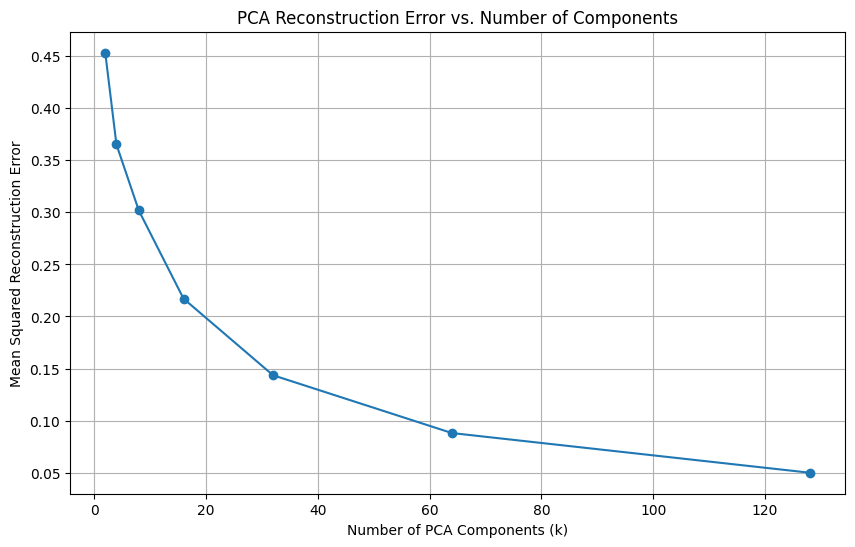

Recommended PCA dimension: k = 64

Reasons:
- The reconstruction error curve shows a clear elbow around 20~60, meaning additional components bring diminishing returns.
- k = 64 balances information preservation (much lower error < 10) and computational stability.
- Higher dimensions (such as 128) significantly increase complexity and make GMM prone to covariance singularity and EM convergence issues.

#### PCA modeling

In [ ]:
pca_dim = 64

pca = PCA(n_components=pca_dim, random_state=0)
pca.fit(all_patches)

#### data generating

In [ ]:
# for GMM
folk_pca = pca.transform(folk_patches)
jazz_pca = pca.transform(jazz_patches)

### **GMM**

In [11]:
import numpy as np
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment
import joblib

#### k-clusters evaluation

In [ ]:
# Ensure necessary data is available (from previous cells)
# folk_pca, jazz_pca

# --- Part 2: Evaluate GMM Components (BIC Criterion) ---
print("Evaluating GMM Components using BIC Criterion...")

# Define a range of GMM components to test
gmm_components_range = range(1, 21) # From 1 to 20 components

folk_bics = []
jazz_bics = []

# Evaluate GMM for Folk data
print("Evaluating GMM for Folk data...")
for n_components in gmm_components_range:
    gmm = GaussianMixture(
        n_components=n_components,
        n_init=1,               # Only 1 initialization for faster evaluation
        reg_covar=1e-2,
        max_iter=100,
        tol=1e-3,
        covariance_type='diag', # Keeping 'diag' as per current model
        random_state=0          # for reproducibility
    )
    gmm.fit(folk_pca)
    folk_bics.append(gmm.bic(folk_pca))
    print(f"Folk GMM components: {n_components}, BIC: {folk_bics[-1]:.2f}")

# Evaluate GMM for Jazz data
print("\nEvaluating GMM for Jazz data...")
for n_components in gmm_components_range:
    gmm = GaussianMixture(
        n_components=n_components,
        n_init=1,
        reg_covar=1e-2,
        max_iter=100,
        tol=1e-3,
        covariance_type='diag',
        random_state=0
    )
    gmm.fit(jazz_pca)
    jazz_bics.append(gmm.bic(jazz_pca))
    print(f"Jazz GMM components: {n_components}, BIC: {jazz_bics[-1]:.2f}")

# Plotting the GMM BIC Scores
plt.figure(figsize=(12, 6))
plt.plot(gmm_components_range, folk_bics, marker='o', linestyle='-', label='Folk GMM BIC')
plt.plot(gmm_components_range, jazz_bics, marker='x', linestyle='--', label='Jazz GMM BIC')
plt.title('GMM Bayesian Information Criterion (BIC) vs. Number of Components')
plt.xlabel('Number of GMM Components')
plt.ylabel('BIC Score (Lower is Better)')
plt.xticks(gmm_components_range)
plt.grid(True)
plt.legend()
plt.show()

##### **Result**

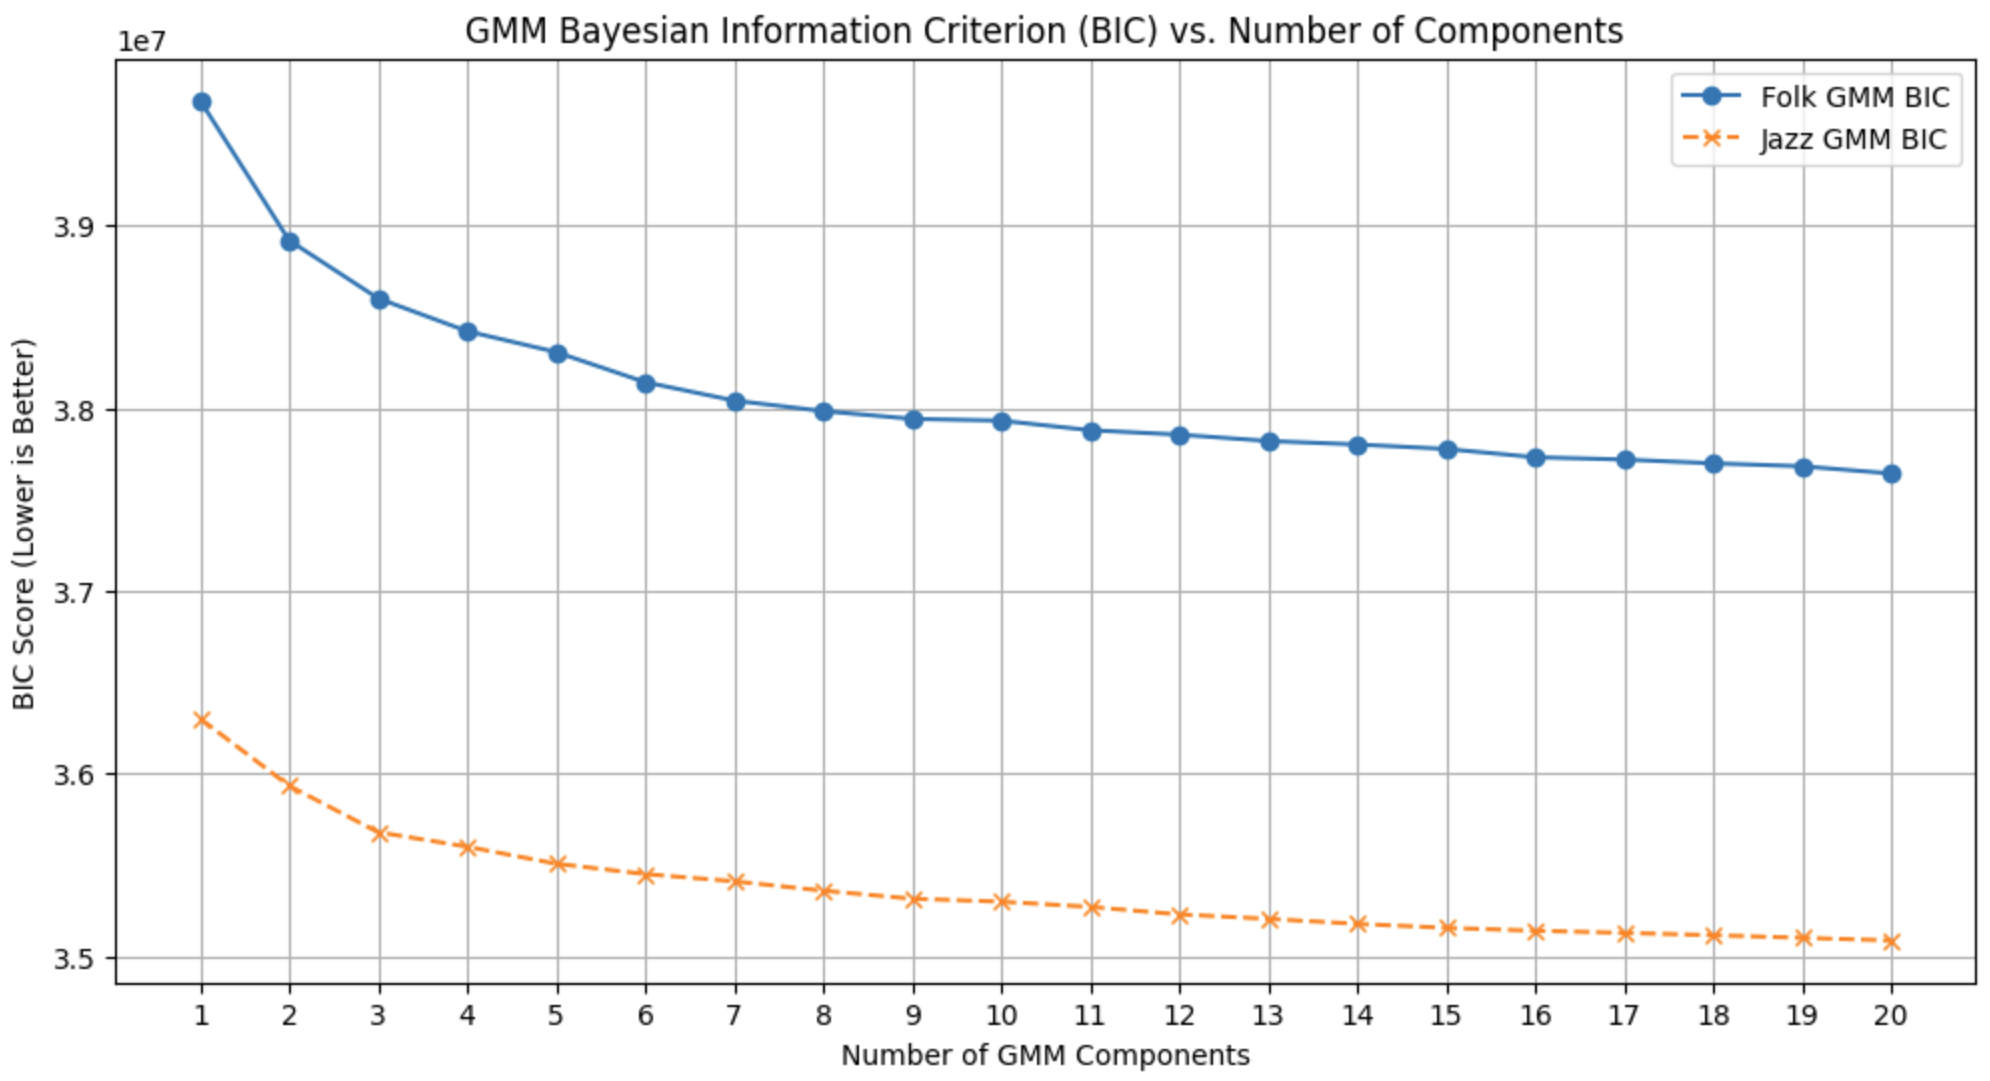

Recommended GMM clusters: k = 8

Reasons:

1. BIC shows a clear diminishing return after n = 8 :
    - From k = 1 → 8, the BIC drops significantly (meaning the model fits better).
    - After k = 8, the BIC curve becomes nearly flat, showing no meaningful improvement.
2. Larger k increases model complexity without improving performance:
    - More parameters → risk of singular covariances
    - Slower EM convergence
    - Higher memory cost
    - No BIC improvement → unnecessary complexity

#### GMM modeling

In [ ]:
k = 8

gmm_folk = GaussianMixture(
    n_components=k,
    covariance_type='full',
    max_iter=200,
    random_state=0
)
gmm_folk.fit(folk_pca)

gmm_jazz = GaussianMixture(
    n_components=k,
    covariance_type='full',
    max_iter=200,
    random_state=0
)
gmm_jazz.fit(jazz_pca)

#### mapping

In [12]:
dist_matrix = cdist(gmm_folk.means_, gmm_jazz.means_, metric='euclidean')
row_ind, col_ind = linear_sum_assignment(dist_matrix)
mapping = {int(r): int(c) for r, c in zip(row_ind, col_ind)}

## **Testing Section**
1. Functions
    - def transform_folk_to_jazz()
    - def plot_mel_spectrogram()
    - def mel_to_wav()

2. Sample Test
    - select one folk sample
        - visualization (spectrogram)
        - audio (.wav)
    - convert to jazz style
        - run transform_folk_to_jazz()
        - idea: x_folk + a * (mu_jazz - mu_folk) = x'_jazz
        - check result (visualization + audio)
    - analysis

3. Test Result Collection ( include all folks samples )
    - load all folk samples
    - convert to jazz style and store them

### Functions

In [5]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

In [26]:
def transform_folk_to_jazz(
    mel_80x616,
    scaler,
    pca,
    gmm_folk,
    gmm_jazz,
    mapping,
    patch_size=20,
    hop=10,
    alpha=5.0
):
    """
    input: folk log-mel (80,616)
    output: converted jazz log-mel (80,616)
    """

    # Step 1: normalization
    mel_norm = scaler.transform(mel_80x616.T).T   # (80,616)

    # Step 2: patches
    patches = []
    positions = []
    T = mel_norm.shape[1]

    for start in range(0, T - patch_size + 1, hop):
        end = start + patch_size
        patches.append(mel_norm[:, start:end])   # (80,20)
        positions.append(start)

    # Step 3: PCA + GMM + style shift
    new_patches = []
    for p in patches:
        vec = p.reshape(1, -1)               # (1,1600)
        z = pca.transform(vec)               # (1,128)

        k_f = gmm_folk.predict(z)[0]         # folk cluster
        k_j = mapping[k_f]                   # matched jazz cluster

        mu_f = gmm_folk.means_[k_f]
        mu_j = gmm_jazz.means_[k_j]

        z_new = z + alpha * (mu_j - mu_f)    # style shift

        vec_new = pca.inverse_transform(z_new)   # (1,1600)
        p_new = vec_new.reshape(80, patch_size)
        new_patches.append(p_new)

    # Step 4: overlap-add (rebuild mel structure)
    mel_new = np.zeros_like(mel_norm)
    counts = np.zeros_like(mel_norm)

    for p_new, start in zip(new_patches, positions):
        end = start + patch_size
        mel_new[:, start:end] += p_new
        counts[:, start:end] += 1

    mel_new /= np.maximum(counts, 1)

    # Step 5: inverse scaler
    mel_final = scaler.inverse_transform(mel_new.T).T

    # Step 6: set limit (dB range -80 ~ 0)
    mel_final = np.clip(mel_final, -80.0, 0.0)

    return mel_final   # log-mel

In [7]:
def plot_mel_spectrogram(mel_log, title="Mel Spectrogram"):
    """
    input: mel_log: (80, T)
    """
    plt.figure(figsize=(10, 4))
    librosa.display.specshow(
        mel_log,
        sr=22050,
        hop_length=512,
        x_axis='time',
        y_axis='mel'
    )
    plt.colorbar(format="%+2.f dB")
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [27]:
def mel_to_wav(mel_log, sr=22050, n_fft=2048, hop_length=358):
    """
    log-mel -> audio waveform (Griffin-Lim)
    input: mel_log (80, T)
    """

    # log-mel → linear mel
    mel_linear = librosa.db_to_power(mel_log)

    # mel → STFT magnitude
    S = librosa.feature.inverse.mel_to_stft(
        mel_linear,
        sr=sr,
        n_fft=n_fft
    )

    # Griffin-Lim 复原 waveform
    wav = librosa.griffinlim(
        S,
        n_iter=60,
        hop_length=hop_length,
        win_length=n_fft
    )

    return wav

### Sample Test

In [20]:
import numpy as np
import joblib
import torch
from IPython.display import Audio

In [4]:
# loaded models
scaler = joblib.load("/content/drive/MyDrive/Music_Project/model_scaler.pkl")
pca = joblib.load("/content/drive/MyDrive/Music_Project/model_pca_64n.pkl")
gmm_folk = joblib.load("/content/drive/MyDrive/Music_Project/model_folk_gmm.pkl")
gmm_jazz = joblib.load("/content/drive/MyDrive/Music_Project/model_jazz_gmm.pkl")
mapping = joblib.load("mapping.pkl")

In [21]:
# load dataset
folk_mels = torch.load("/content/drive/MyDrive/5200 Final project/EVALUTION/folkdataset.pt")

In [28]:
# choose one folk sample
sample_id = 0
sample_logmel = folk_mels['folk_feature'][0].numpy()      # (80, 616)

# style transform to jazz
mel_jazz_log = transform_folk_to_jazz(
    mel_80x616 = sample_logmel,
    scaler     = scaler,
    pca        = pca,
    gmm_folk   = gmm_folk,
    gmm_jazz   = gmm_jazz,
    mapping    = mapping,
    patch_size = 20,
    hop        = 10,
    alpha      = 3.0        # choose the amplifier for style differences (1~10)
)

# rebuild .wav (Griffin-Lim)
wav_original = mel_to_wav(sample_logmel)
wav_jazz     = mel_to_wav(mel_jazz_log)

Original log mel:
[[-64.28133  -56.593193 -59.211266 ... -43.582863 -43.252235 -44.888653]
 [-67.481476 -60.4162   -63.682423 ... -29.214283 -29.877571 -33.88207 ]
 [-71.256134 -64.75154  -63.94193  ... -25.606894 -23.784346 -26.453894]
 ...
 [-73.07962  -59.415627 -55.697777 ... -58.284164 -60.182457 -59.413937]
 [-73.236145 -62.757256 -58.029976 ... -53.97506  -54.10696  -54.902504]
 [-75.986305 -67.96895  -64.23755  ... -60.618774 -59.5905   -59.178715]]
Converted log mel:
[[-42.105003 -38.691654 -36.427685 ... -31.662416 -31.662416 -31.662416]
 [-44.18085  -40.557827 -38.105747 ... -26.597055 -26.597055 -26.597055]
 [-50.70757  -46.873844 -44.40046  ... -26.834568 -26.834568 -26.834568]
 ...
 [-47.65009  -41.94707  -38.03057  ... -62.2853   -62.2853   -62.2853  ]
 [-44.474426 -38.755745 -34.794956 ... -63.33818  -63.33818  -63.33818 ]
 [-48.36923  -43.517937 -39.98045  ... -68.47794  -68.47794  -68.47794 ]]
Original spectrogram:


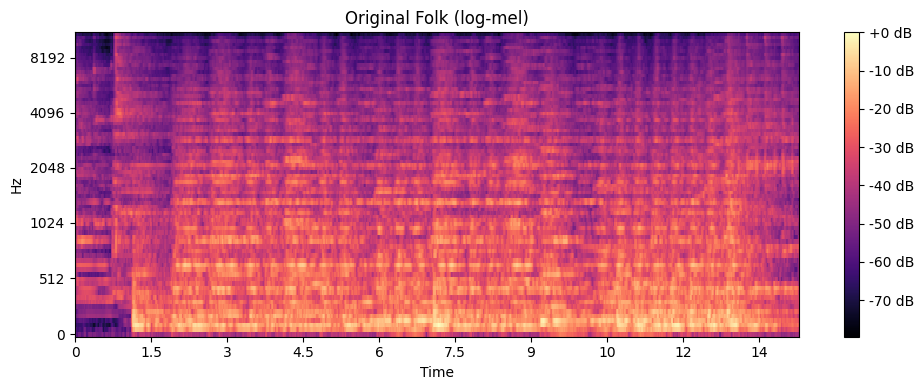

Converted spectrogram:


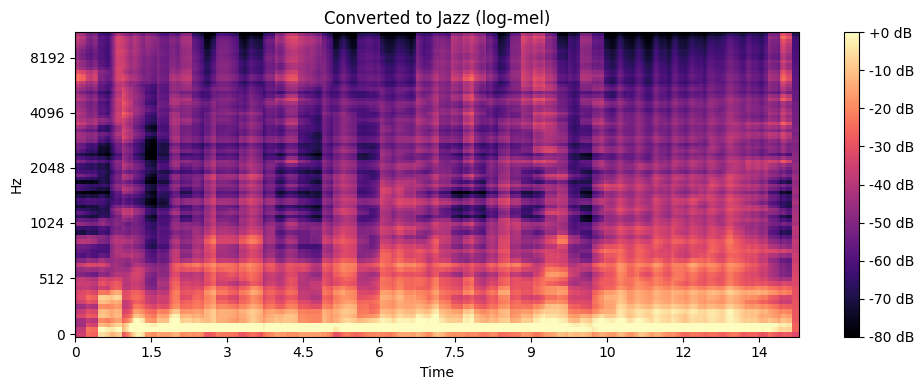

Play original:


Play converted:


In [29]:
# mel comparison
print("Original log mel:")
print(sample_logmel)

print("Converted log mel:")
print(mel_jazz_log)

# visualization comparison
print("Original spectrogram:")
plot_mel_spectrogram(sample_logmel, title="Original Folk (log-mel)")

print("Converted spectrogram:")
plot_mel_spectrogram(mel_jazz_log, title="Converted to Jazz (log-mel)")

# audio comparison
print("Play original:")
display(Audio(wav_original, rate=22050))

print("Play converted:")
display(Audio(wav_jazz, rate=22050))

### Test Result Collection ( include all folks samples )

In [32]:
from tqdm import tqdm
import numpy as np
import torch

In [33]:
# load dataset
folk_mels = torch.load("/content/drive/MyDrive/5200 Final project/EVALUTION/folkdataset.pt")

# load models
scaler = joblib.load("/content/drive/MyDrive/Music_Project/model_scaler.pkl")
pca = joblib.load("/content/drive/MyDrive/Music_Project/model_pca_64n.pkl")
gmm_folk = joblib.load("/content/drive/MyDrive/Music_Project/model_folk_gmm.pkl")
gmm_jazz = joblib.load("/content/drive/MyDrive/Music_Project/model_jazz_gmm.pkl")
mapping = joblib.load("/content/drive/MyDrive/Music_Project/mapping.pkl")

In [37]:
folk_data = folk_mels['folk_feature']
N = folk_data.shape[0]
converted_mels = np.zeros_like(folk_data)    # (N, 80, 616)

print("Starting batch style transfer...")
for i in tqdm(range(N)):
    mel_log = folk_data[i]   # (80,616)

    mel_jazz_log = transform_folk_to_jazz(
        mel_80x616 = mel_log,
        scaler     = scaler,
        pca        = pca,
        gmm_folk   = gmm_folk,
        gmm_jazz   = gmm_jazz,
        mapping    = mapping,
        patch_size = 20,
        hop        = 10,
        alpha      = 3.0
    )

    converted_mels[i] = mel_jazz_log

print("Batch conversion finished.")

Starting batch style transfer...


100%|██████████| 2207/2207 [01:55<00:00, 19.16it/s]

Batch conversion finished.


In [39]:
save_dict = {
    "original": folk_mels,          # original log-mel (N, 80, 616)
    "converted": converted_mels,    # converted log-mel (N, 80, 616)
}

torch.save(save_dict, "/content/drive/MyDrive/5200 Final project/EVALUTION/PCA_GMM_Result.pt")
print("Saved to folk_jazz_conversion.pt")

Saved to folk_jazz_conversion.pt


In [40]:
converted_mels

array([[[-42.104996, -38.69165 , -36.42768 , ..., -31.662416,
         -31.662416, -31.662416],
        [-44.180847, -40.557823, -38.10574 , ..., -26.597055,
         -26.597055, -26.597055],
        [-50.707565, -46.87384 , -44.400455, ..., -26.834568,
         -26.834568, -26.834568],
        ...,
        [-47.65009 , -41.94707 , -38.03057 , ..., -62.2853  ,
         -62.2853  , -62.2853  ],
        [-44.474426, -38.755745, -34.794956, ..., -63.33818 ,
         -63.33818 , -63.33818 ],
        [-48.369225, -43.517937, -39.980446, ..., -68.47794 ,
         -68.47794 , -68.47794 ]],

       [[-43.75761 , -45.281796, -46.8273  , ..., -31.662416,
         -31.662416, -31.662416],
        [-32.17319 , -33.659805, -35.123802, ..., -26.597055,
         -26.597055, -26.597055],
        [-39.859993, -41.61086 , -43.094486, ..., -26.834568,
         -26.834568, -26.834568],
        ...,
        [-64.68972 , -68.484436, -71.293106, ..., -62.2853  ,
         -62.2853  , -62.2853  ],
        [-65

####